PREDICTING HOUSE PRICES WITH LINEAR REGRESSION

1. 1. IMPORT LIBRARIES

In [26]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


2. DOWNLOAD DATASET DIRECTLY FROM KAGGLE

In [27]:

import kagglehub
import pandas as pd
import os

# Download the latest dataset directly from Kaggle
dataset_path = kagglehub.dataset_download(
    "shashanknecrothapa/ames-housing-dataset"
)

print("Dataset downloaded to:", dataset_path)

# Display available files
print("\nAvailable files:")
for file in os.listdir(dataset_path):
    print(file)

# Find CSV files
csv_files = [
    file for file in os.listdir(dataset_path)
    if file.lower().endswith(".csv")
]

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found in the Kaggle dataset."
    )

# Prefer a housing dataset file, if available
file_name = next(
    (
        file for file in csv_files
        if "ames" in file.lower()
        or "housing" in file.lower()
    ),
    csv_files[0]
)

file_path = os.path.join(dataset_path, file_name)

# Load the dataset
df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("File:", file_name)
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())


# Standardize column names for the existing project

column_mapping = {
    "Sale Price": "SalePrice",
    "Gr Liv Area": "GrLivArea",
    "Overall Qual": "OverallQual",
    "Total Bsmt SF": "TotalBsmtSF",
    "Garage Cars": "GarageCars",
    "Bedroom AbvGr": "BedroomAbvGr",
    "Full Bath": "FullBath",
    "TotRms AbvGrd": "TotRmsAbvGrd",
    "TotRms Abv Grd": "TotRmsAbvGrd",
    "Lot Area": "LotArea",
    "Year Built": "YearBuilt",
    "Yr Sold": "YrSold",
    "Overall Cond": "OverallCond",
    "House Style": "HouseStyle",
    "Central Air": "CentralAir"
}

df.columns = df.columns.str.strip()

df = df.rename(columns=column_mapping)

# Verify required features
required_columns = [
    "SalePrice",
    "GrLivArea",
    "OverallQual",
    "TotalBsmtSF",
    "GarageCars",
    "BedroomAbvGr",
    "FullBath",
    "TotRmsAbvGrd",
    "LotArea",
    "YearBuilt",
    "YrSold",
    "OverallCond",
    "Neighborhood",
    "HouseStyle",
    "CentralAir"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Missing required columns:", missing_columns)
else:
    print("All required columns are available!")
    print("You can continue with Step 3 of your project.")


Using Colab cache for faster access to the 'ames-housing-dataset' dataset.
Dataset downloaded to: /kaggle/input/ames-housing-dataset

Available files:
AmesHousing.csv

Dataset loaded successfully!
File: AmesHousing.csv
Dataset shape: (2930, 82)

First 5 rows:
   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0 

3. INITIAL DATA INSPECTION

In [28]:
print("\nMissing values per column:")
print(
    df.isnull().sum()
    .sort_values(ascending=False)
    .head(30)
)

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDescriptive statistics:")
print(df.describe().T)

print("\nCategorical statistics:")
print(df.describe(include="object").T)

print("\nSalePrice statistics:")
print(df["SalePrice"].describe())

print("\nMean House Price:")
print(df["SalePrice"].mean())

print("\nMedian House Price:")
print(df["SalePrice"].median())

print("\nStandard Deviation:")
print(df["SalePrice"].std())


Missing values per column:
Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Yr Blt      159
Garage Cond        159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Qual           80
Bsmt Cond           80
BsmtFin Type 1      80
Mas Vnr Area        23
Bsmt Full Bath       2
Bsmt Half Bath       2
TotalBsmtSF          1
BsmtFin SF 1         1
BsmtFin SF 2         1
Garage Area          1
GarageCars           1
Bsmt Unf SF          1
Electrical           1
Lot Shape            0
Street               0
LotArea              0
dtype: int64

Duplicate rows:
0

Descriptive statistics:
                  count          mean           std          min  \
Order            2930.0  1.465500e+03  8.459625e+02          1.0   
PID              2930.0  7.144645e+08  1.887308e+08  526301100.0   
MS SubClass      2930

4. VISUALISE HOUSE PRICE DISTRIBUTION

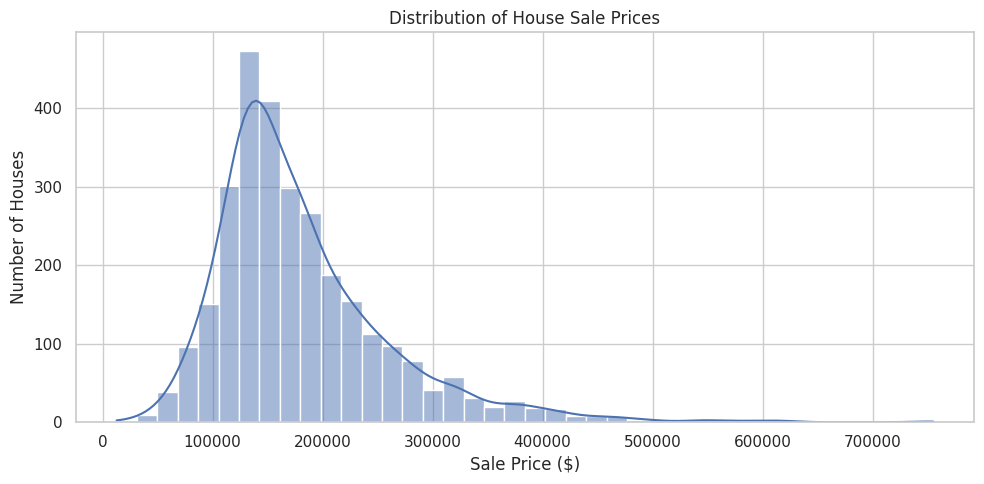

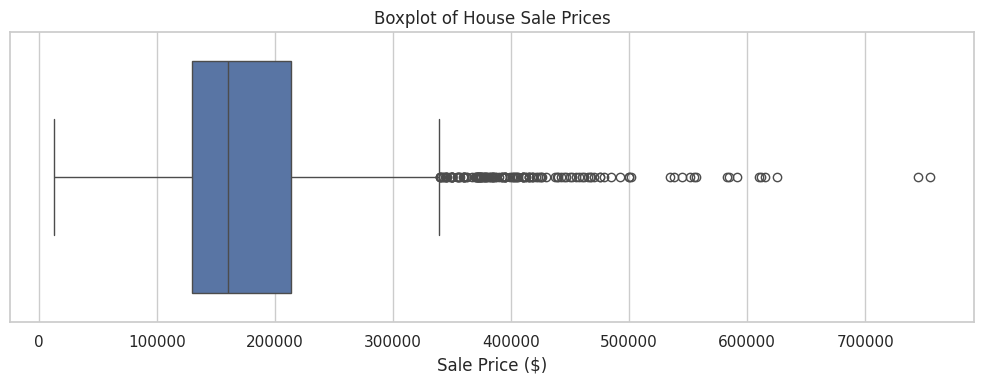


SalePrice skewness: 1.744


In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["SalePrice"],
    bins=40,
    kde=True
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

# Boxplot to identify outliers
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["SalePrice"]
)

plt.title("Boxplot of House Sale Prices")
plt.xlabel("Sale Price ($)")

plt.tight_layout()
plt.show()

print(
    "\nSalePrice skewness:",
    round(df["SalePrice"].skew(), 3)
)

# Observation:
# Check whether the distribution is right-skewed.
# Some expensive houses may appear as outliers.

5. FEATURE ENGINEERING

In [30]:
data = df.copy()

# HouseAge indicates how old the house was
# at the time it was sold.

data["HouseAge"] = (
    data["YrSold"] - data["YearBuilt"]
)

# Avoid using a negative age if inconsistent
# source data is encountered.
data.loc[
    data["HouseAge"] < 0,
    "HouseAge"
] = np.nan

6. FEATURE SELECTION

In [31]:
# Choose meaningful numerical and categorical predictors.
#
# GrLivArea: Above-ground living area
# OverallQual: Overall material/finish quality
# TotalBsmtSF: Basement area
# GarageCars: Garage capacity
# BedroomAbvGr: Bedrooms above ground
# FullBath: Number of full bathrooms
# TotRmsAbvGrd: Total rooms above ground
# LotArea: Lot size
# HouseAge: Age at sale
# OverallCond: Overall condition
#
# Neighborhood: Location of property
# HouseStyle: Building style
# CentralAir: Air-conditioning availability

numeric_features = [
    "GrLivArea",
    "OverallQual",
    "TotalBsmtSF",
    "GarageCars",
    "BedroomAbvGr",
    "FullBath",
    "TotRmsAbvGrd",
    "LotArea",
    "HouseAge",
    "OverallCond"
]

categorical_features = [
    "Neighborhood",
    "HouseStyle",
    "CentralAir"
]

selected_features = (
    numeric_features + categorical_features
)

target = "SalePrice"

print("\nSelected numerical features:")
print(numeric_features)

print("\nSelected categorical features:")
print(categorical_features)

print("\nTarget:", target)

print("""
Feature selection explanation:

House size, overall quality, basement size,
garage capacity, bedroom count, bathrooms,
condition, house age and neighborhood may
influence property selling prices.

Categorical features require encoding before
they can be used by Linear Regression.
""")



Selected numerical features:
['GrLivArea', 'OverallQual', 'TotalBsmtSF', 'GarageCars', 'BedroomAbvGr', 'FullBath', 'TotRmsAbvGrd', 'LotArea', 'HouseAge', 'OverallCond']

Selected categorical features:
['Neighborhood', 'HouseStyle', 'CentralAir']

Target: SalePrice

Feature selection explanation:

House size, overall quality, basement size,
garage capacity, bedroom count, bathrooms,
condition, house age and neighborhood may
influence property selling prices.

Categorical features require encoding before
they can be used by Linear Regression.



7. CORRELATION ANALYSIS


Correlation with SalePrice:
SalePrice       1.000000
OverallQual     0.799262
GrLivArea       0.706780
GarageCars      0.647877
TotalBsmtSF     0.632280
FullBath        0.545604
TotRmsAbvGrd    0.495474
LotArea         0.266549
BedroomAbvGr    0.143913
OverallCond    -0.101697
HouseAge       -0.559037
Name: SalePrice, dtype: float64


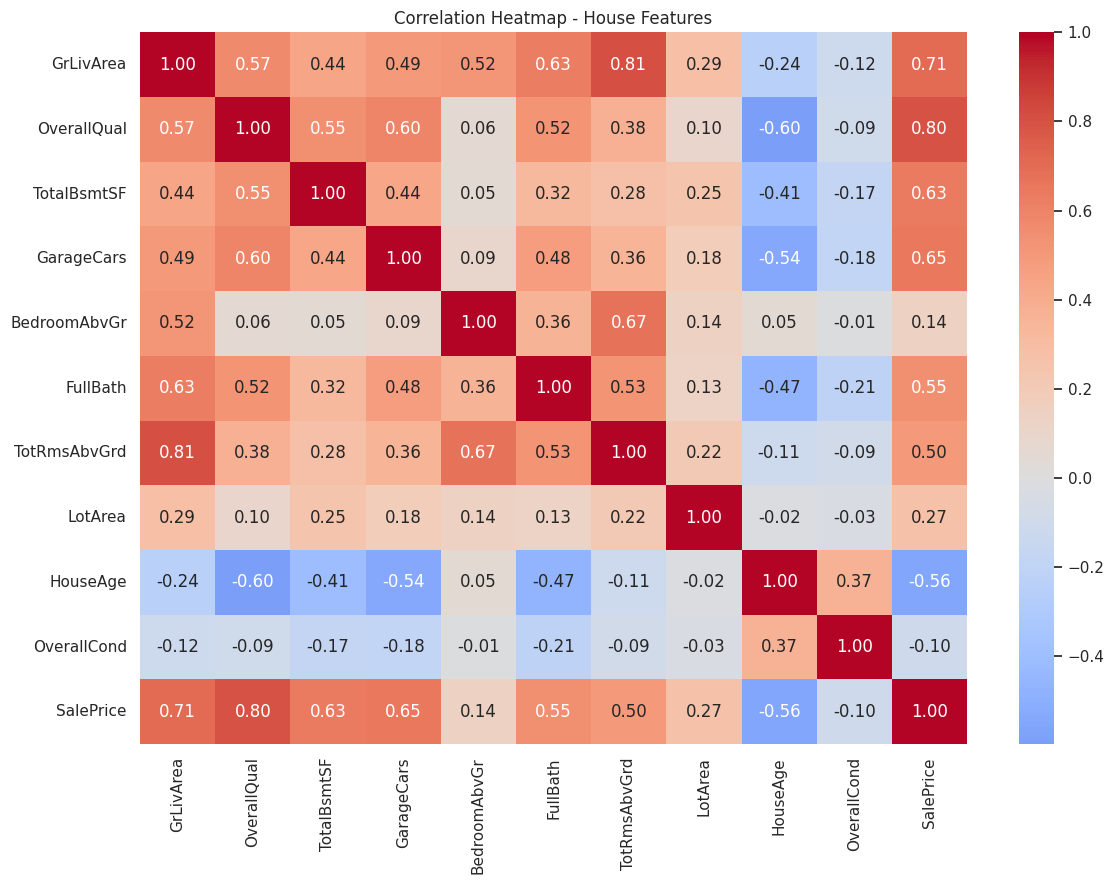


Numerical features ranked by correlation:
OverallQual     0.799262
GrLivArea       0.706780
GarageCars      0.647877
TotalBsmtSF     0.632280
HouseAge       -0.559037
FullBath        0.545604
TotRmsAbvGrd    0.495474
LotArea         0.266549
BedroomAbvGr    0.143913
OverallCond    -0.101697
Name: SalePrice, dtype: float64


In [32]:
correlation_columns = (
    numeric_features + ["SalePrice"]
)

corr = data[
    correlation_columns
].corr()

print("\nCorrelation with SalePrice:")
print(
    corr["SalePrice"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap - House Features")
plt.tight_layout()
plt.show()

# Rank numerical features by absolute correlation
price_correlations = (
    corr["SalePrice"]
    .drop("SalePrice")
    .sort_values(key=abs, ascending=False)
)

print("\nNumerical features ranked by correlation:")
print(price_correlations)

8. ADDITIONAL EDA VISUALIZATIONS

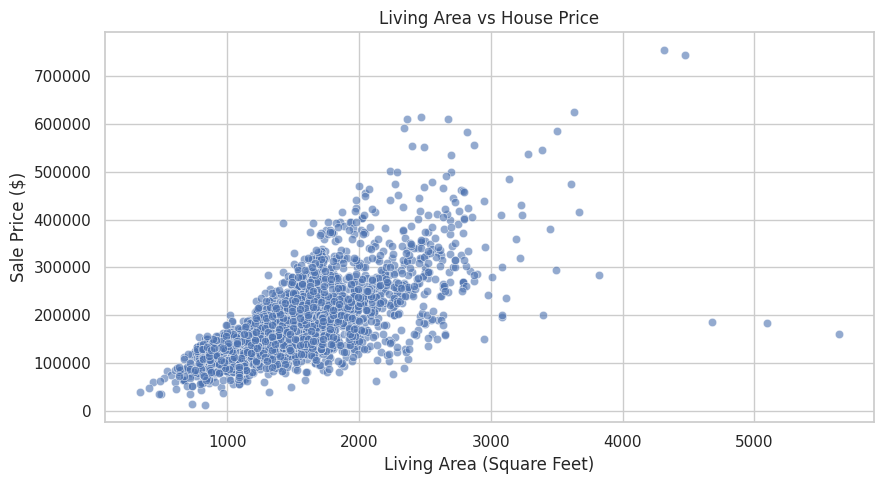

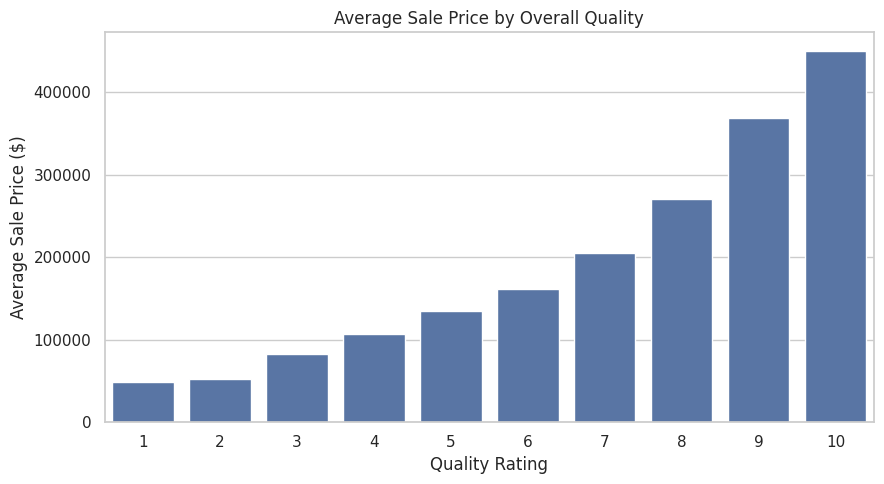

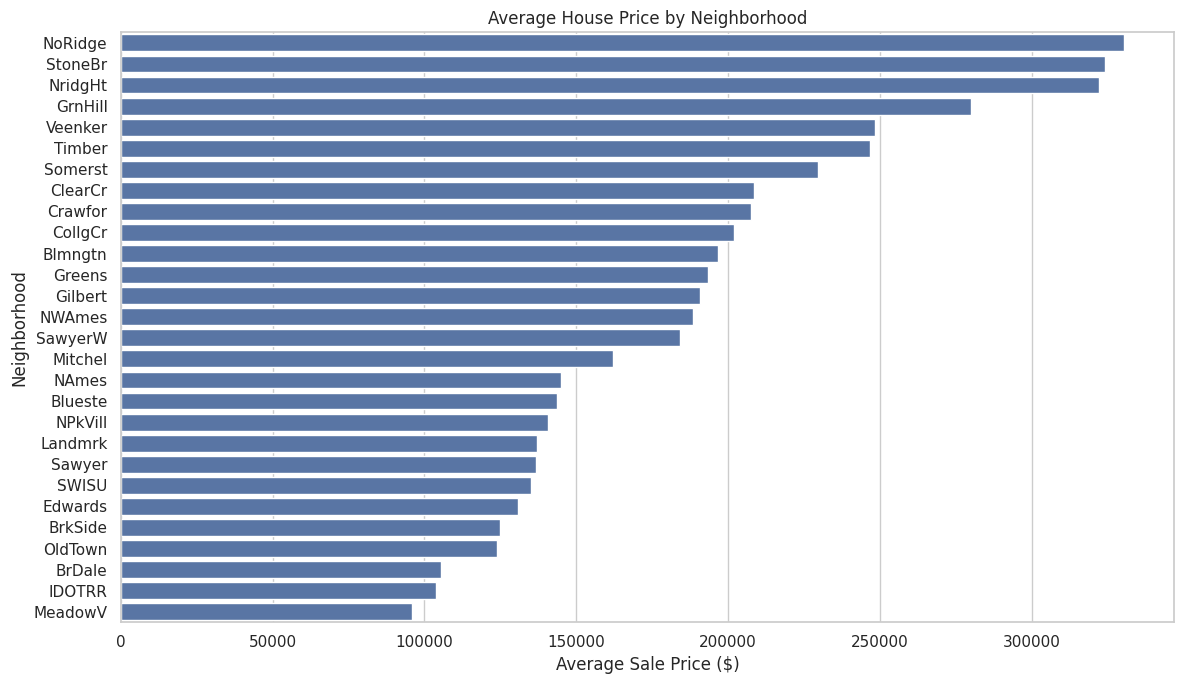

In [33]:
# A. Living area vs SalePrice
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=data,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.6
)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()

# B. Overall quality vs average house price
quality_prices = (
    data.groupby("OverallQual")["SalePrice"]
    .mean()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=quality_prices.index,
    y=quality_prices.values
)

plt.title("Average Sale Price by Overall Quality")
plt.xlabel("Quality Rating")
plt.ylabel("Average Sale Price ($)")

plt.tight_layout()
plt.show()

# C. Average sale price by neighborhood
neighborhood_prices = (
    data.groupby("Neighborhood")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=neighborhood_prices.values,
    y=neighborhood_prices.index
)

plt.title("Average House Price by Neighborhood")
plt.xlabel("Average Sale Price ($)")
plt.ylabel("Neighborhood")

plt.tight_layout()
plt.show()


9. PREPARE FEATURES AND TARGET

In [34]:
X = data[selected_features].copy()
y = data[target].copy()

# Remove records with unknown target prices.
valid_rows = y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows]

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (2930, 13)
Target shape: (2930,)


10. TRAIN-TEST SPLIT

In [35]:
X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=RANDOM_STATE
    )
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))



Training samples: 2344
Testing samples: 586


11. HANDLE MISSING VALUES AND ONE HOT ENCODING

In [36]:
# Numeric:
# Median imputation + StandardScaler
#
# Categorical:
# Most frequent imputation + One-Hot Encoding
#
# The preprocessing pipeline fits only on
# training data to prevent data leakage.

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
                sparse_output=False
            )
        )
    ]
)

def make_preprocessor():

    return ColumnTransformer(
        transformers=[
            (
                "num",
                numeric_transformer,
                numeric_features
            ),
            (
                "cat",
                categorical_transformer,
                categorical_features
            )
        ]
    )


12. TRAIN LINEAR REGRESSION MODEL

In [37]:
linear_model = Pipeline(
    steps=[
        (
            "preprocessor",
            make_preprocessor()
        ),
        (
            "model",
            LinearRegression()
        )
    ]
)

linear_model.fit(
    X_train,
    y_train
)

print("\nLinear Regression trained successfully!")



Linear Regression trained successfully!


13. PREDICT HOUSE PRICES

In [38]:
y_pred = linear_model.predict(
    X_test
)

prediction_results = pd.DataFrame({
    "ActualPrice": y_test.to_numpy(),
    "PredictedPrice": y_pred
})

prediction_results["Error"] = (
    prediction_results["ActualPrice"]
    - prediction_results["PredictedPrice"]
)

prediction_results["AbsoluteError"] = (
    prediction_results["Error"].abs()
)

print("\nFirst 10 predictions:")
print(prediction_results.head(10).round(2))



First 10 predictions:
   ActualPrice  PredictedPrice     Error  AbsoluteError
0       161000       173321.03 -12321.03       12321.03
1       116000       110706.84   5293.16        5293.16
2       196500       199772.89  -3272.89        3272.89
3       123600       107658.77  15941.23       15941.23
4       126000       132729.39  -6729.39        6729.39
5       174190       184023.27  -9833.27        9833.27
6       200000       165141.88  34858.12       34858.12
7       148500       146383.78   2116.22        2116.22
8        88750        98658.04  -9908.04        9908.04
9       409900       340098.73  69801.27       69801.27


14. EVALUATE LINEAR REGRESSION MODEL

In [39]:
mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

mae = mean_absolute_error(
    y_test,
    y_pred
)

r2 = r2_score(
    y_test,
    y_pred
)

print("\nLINEAR REGRESSION EVALUATION")
print("=" * 50)

print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))
print("R2 Score:", round(r2, 4))

print("""
Metric interpretation:

MSE:
Average squared prediction error.

RMSE:
Typical error magnitude, expressed in dollars,
with extra weight on large errors.

R2:
Proportion of variation explained relative
to a mean-price prediction baseline.

A higher R2 is generally better.
A lower MSE and RMSE is generally better.
""")



LINEAR REGRESSION EVALUATION
MSE: 1232797427.34
RMSE: 35111.22
MAE: 20363.66
R2 Score: 0.8462

Metric interpretation:

MSE:
Average squared prediction error.

RMSE:
Typical error magnitude, expressed in dollars,
with extra weight on large errors.

R2:
Proportion of variation explained relative
to a mean-price prediction baseline.

A higher R2 is generally better.
A lower MSE and RMSE is generally better.



15. ACTUAL VS PREDICTED SCATTERPLOT

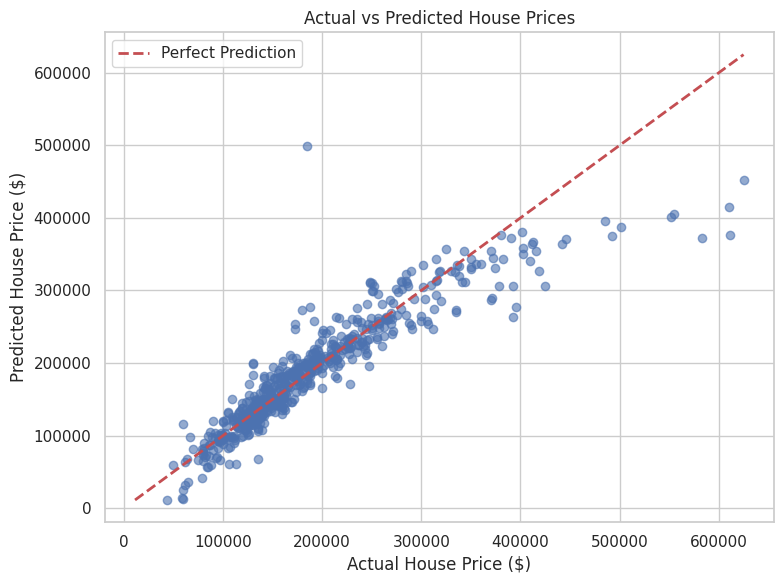

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

min_price = min(
    y_test.min(),
    y_pred.min()
)

max_price = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Price ($)")
plt.ylabel("Predicted House Price ($)")
plt.legend()

plt.tight_layout()
plt.show()


16. RESIDUAL ANALYSIS


Residual statistics:
count       586.000000
mean       2620.798753
std       35043.179737
min     -313658.714270
25%      -12105.475271
50%         912.330820
75%       12516.301745
max      235660.309800
dtype: float64


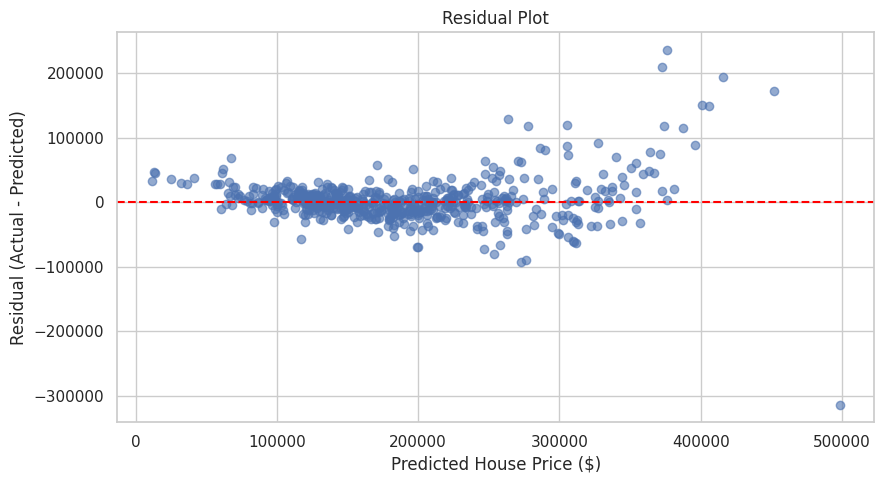

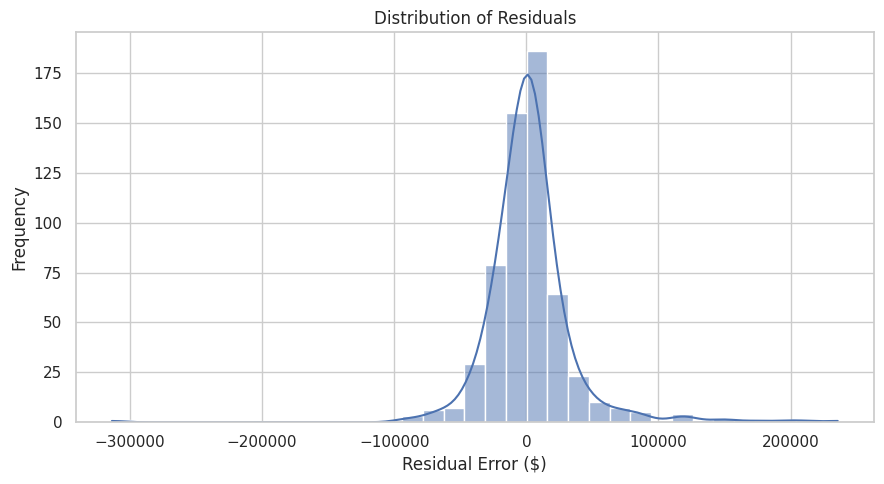

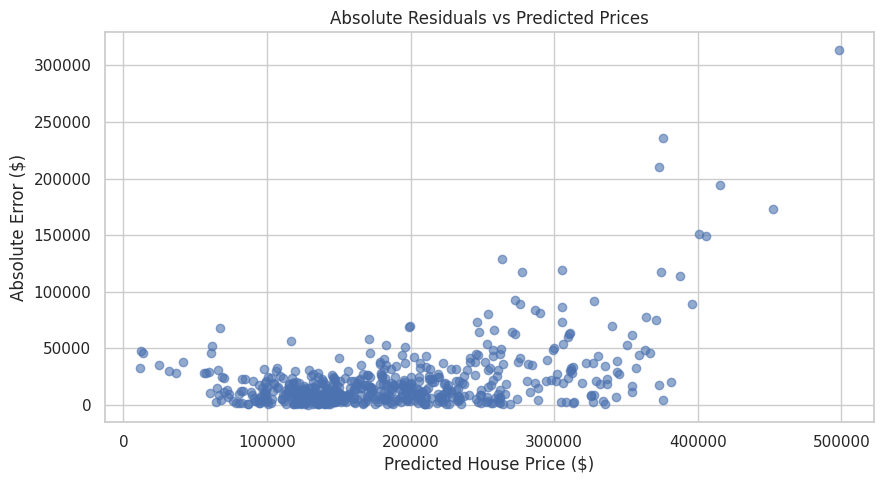


Residual interpretation:

Ideally, residuals should be scattered around zero
without a clear curved pattern.

A funnel shape may suggest non-constant error variance.

Large outliers may indicate properties that the
linear model struggles to predict accurately.



In [41]:
# Residual = Actual Price - Predicted Price

residuals = (
    y_test.to_numpy() - y_pred
)

print("\nResidual statistics:")
print(
    pd.Series(residuals).describe()
)

# A. Residuals vs predicted values
plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residual Plot")
plt.xlabel("Predicted House Price ($)")
plt.ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

# B. Residual distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    bins=35,
    kde=True
)

plt.title("Distribution of Residuals")
plt.xlabel("Residual Error ($)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# C. Does error magnitude change with price?
plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred,
    np.abs(residuals),
    alpha=0.6
)

plt.title("Absolute Residuals vs Predicted Prices")
plt.xlabel("Predicted House Price ($)")
plt.ylabel("Absolute Error ($)")

plt.tight_layout()
plt.show()

print("""
Residual interpretation:

Ideally, residuals should be scattered around zero
without a clear curved pattern.

A funnel shape may suggest non-constant error variance.

Large outliers may indicate properties that the
linear model struggles to predict accurately.
""")

17. LINEAR REGRESSION COEFFICIENT ANALYSIS


Top 10 Positive Coefficients:
                      Feature    Coefficient  AbsoluteCoefficient
19  cat__Neighborhood_GrnHill  107417.910969        107417.910969
34  cat__Neighborhood_StoneBr   77651.648428         77651.648428
28  cat__Neighborhood_NridgHt   64447.524655         64447.524655
27  cat__Neighborhood_NoRidge   64104.655717         64104.655717
15  cat__Neighborhood_Crawfor   36471.578055         36471.578055
0              num__GrLivArea   32581.462294         32581.462294
35   cat__Neighborhood_Timber   26345.228176         26345.228176
33  cat__Neighborhood_Somerst   26232.570350         26232.570350
36  cat__Neighborhood_Veenker   23956.556663         23956.556663
13  cat__Neighborhood_ClearCr   23171.412104         23171.412104

Top 10 Negative Coefficients:
                      Feature   Coefficient  AbsoluteCoefficient
8               num__HouseAge -14759.929046         14759.929046
10  cat__Neighborhood_Blueste -10262.494627         10262.494627
39     cat__House

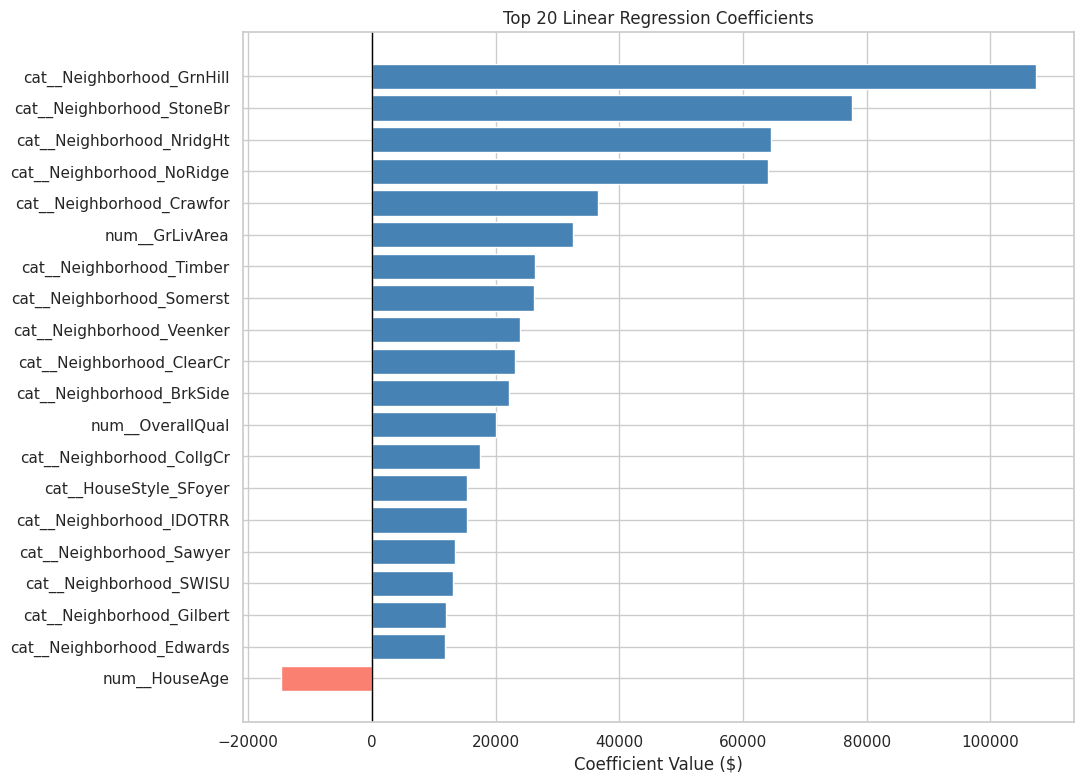


Coefficient interpretation:

Positive coefficient:
Higher predictor values are associated with
higher predicted selling prices, when other
model variables are held constant.

Negative coefficient:
Higher predictor values are associated with
lower predicted selling prices, when other
model variables are held constant.

Numeric variables were standardized.
Their coefficients describe a one-standard-
deviation increase in that variable.

One-hot categorical coefficients represent
differences from an omitted reference category.

The coefficients indicate associations, not
proof that a feature causes a price change.

Multicollinearity can make coefficients unstable.



In [42]:
trained_preprocessor = (
    linear_model.named_steps["preprocessor"]
)

trained_regressor = (
    linear_model.named_steps["model"]
)

feature_names = (
    trained_preprocessor.get_feature_names_out()
)

coefficients = trained_regressor.coef_

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["AbsoluteCoefficient"] = (
    coefficient_df["Coefficient"].abs()
)

print("\nTop 10 Positive Coefficients:")
print(
    coefficient_df.sort_values(
        "Coefficient",
        ascending=False
    ).head(10)
)

print("\nTop 10 Negative Coefficients:")
print(
    coefficient_df.sort_values(
        "Coefficient",
        ascending=True
    ).head(10)
)

# Plot largest positive and negative effects
top_coefficients = (
    coefficient_df
    .sort_values(
        "AbsoluteCoefficient",
        ascending=False
    )
    .head(20)
    .sort_values("Coefficient")
)

plt.figure(figsize=(11, 8))

colors = np.where(
    top_coefficients["Coefficient"] >= 0,
    "steelblue",
    "salmon"
)

plt.barh(
    top_coefficients["Feature"],
    top_coefficients["Coefficient"],
    color=colors
)

plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

plt.title("Top 20 Linear Regression Coefficients")
plt.xlabel("Coefficient Value ($)")

plt.tight_layout()
plt.show()

print("""
Coefficient interpretation:

Positive coefficient:
Higher predictor values are associated with
higher predicted selling prices, when other
model variables are held constant.

Negative coefficient:
Higher predictor values are associated with
lower predicted selling prices, when other
model variables are held constant.

Numeric variables were standardized.
Their coefficients describe a one-standard-
deviation increase in that variable.

One-hot categorical coefficients represent
differences from an omitted reference category.

The coefficients indicate associations, not
proof that a feature causes a price change.

Multicollinearity can make coefficients unstable.
""")


18. RIDGE AND LASSO REGRESSIONS

In [43]:
# Ridge adds L2 regularization.
# Lasso adds L1 regularization.
#
# These models may improve generalization and
# stabilize coefficients for correlated features.

ridge_model = Pipeline(
    steps=[
        (
            "preprocessor",
            make_preprocessor()
        ),
        (
            "model",
            Ridge(
                alpha=100,
                random_state=RANDOM_STATE
            )
        )
    ]
)

lasso_model = Pipeline(
    steps=[
        (
            "preprocessor",
            make_preprocessor()
        ),
        (
            "model",
            Lasso(
                alpha=500,
                max_iter=30000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

ridge_model.fit(
    X_train,
    y_train
)

lasso_model.fit(
    X_train,
    y_train
)

print("\nRidge and Lasso models trained!")



Ridge and Lasso models trained!


19. COMPARE ALL THREE MODELS


MODEL COMPARISON
            Model          MSE      RMSE       MAE    R2
Linear Regression 1.232797e+09 35111.215 20363.660 0.846
 Ridge Regression 1.345942e+09 36687.076 21876.455 0.832
 Lasso Regression 1.336301e+09 36555.453 22143.213 0.833


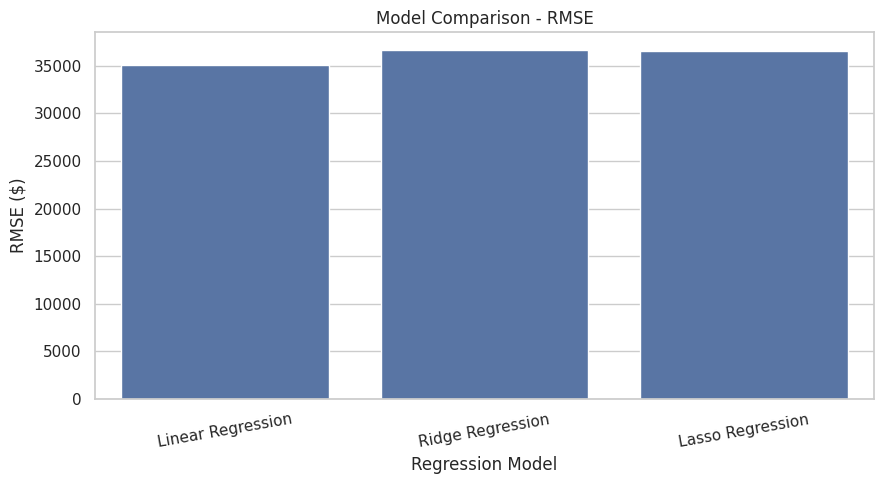

In [44]:
models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model
}

comparison_rows = []

for model_name, model in models.items():

    predictions = model.predict(X_test)

    model_mse = mean_squared_error(
        y_test, predictions
    )

    comparison_rows.append({
        "Model": model_name,
        "MSE": model_mse,
        "RMSE": np.sqrt(model_mse),
        "MAE": mean_absolute_error(
            y_test, predictions
        ),
        "R2": r2_score(
            y_test, predictions
        )
    })

comparison_df = pd.DataFrame(
    comparison_rows
)

print("\nMODEL COMPARISON")
print("=" * 60)

print(
    comparison_df.round(3).to_string(
        index=False
    )
)

# Plot RMSE comparison
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison - RMSE")
plt.xlabel("Regression Model")
plt.ylabel("RMSE ($)")

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

20. BEST MODEL

In [45]:
best_model_row = (
    comparison_df
    .sort_values("RMSE")
    .iloc[0]
)

print("\nLOWEST RMSE MODEL:")
print(best_model_row["Model"])

print("\nModel performance:")
print(best_model_row.to_string())

print("""
Note:
This comparison uses a common held-out test set.

For a more rigorous study, tune model parameters
using cross-validation on training data and use
the test set only for final evaluation.
""")


LOWEST RMSE MODEL:
Linear Regression

Model performance:
Model    Linear Regression
MSE      1232797427.338201
RMSE          35111.215122
MAE           20363.659936
R2                0.846238

Note:
This comparison uses a common held-out test set.

For a more rigorous study, tune model parameters
using cross-validation on training data and use
the test set only for final evaluation.



21. SAVE RESULTS TO CSV

In [46]:
prediction_results.to_csv(
    "house_price_predictions.csv",
    index=False
)

coefficient_df.to_csv(
    "linear_regression_coefficients.csv",
    index=False
)

comparison_df.to_csv(
    "house_price_model_comparison.csv",
    index=False
)

print("\nFiles saved successfully:")
print("1. house_price_predictions.csv")
print("2. linear_regression_coefficients.csv")
print("3. house_price_model_comparison.csv")


Files saved successfully:
1. house_price_predictions.csv
2. linear_regression_coefficients.csv
3. house_price_model_comparison.csv


FINAL PROJECT SUMMARY

In [47]:
print("\nHOUSE PRICE PREDICTION - FINAL SUMMARY")
print("=" * 60)

print("Dataset: Ames Housing")
print("Source: Kaggle")
print("Total houses:", len(df))
print("Training houses:", len(X_train))
print("Testing houses:", len(X_test))

print(
    "\nLinear Regression RMSE:",
    round(rmse, 2)
)

print(
    "Linear Regression R2:",
    round(r2, 4)
)

print(
    "\nBest comparison model:",
    best_model_row["Model"]
)

print("""
PROJECT CONCLUSION:

The project predicts house selling prices using
property characteristics such as living area,
overall quality, location, house age, basement
size, number of rooms and garage capacity.

Data was inspected, missing values were handled,
categorical variables were one-hot encoded,
and an 80/20 train-test split was performed.

Linear Regression was evaluated using MSE,
RMSE and R2. Residual plots were used to
investigate prediction errors.

Ridge and Lasso Regression were also compared
as optional regularized alternatives.

The model coefficients help explain which
features are positively or negatively
associated with predicted property prices.
""")


HOUSE PRICE PREDICTION - FINAL SUMMARY
Dataset: Ames Housing
Source: Kaggle
Total houses: 2930
Training houses: 2344
Testing houses: 586

Linear Regression RMSE: 35111.22
Linear Regression R2: 0.8462

Best comparison model: Linear Regression

PROJECT CONCLUSION:

The project predicts house selling prices using
property characteristics such as living area,
overall quality, location, house age, basement
size, number of rooms and garage capacity.

Data was inspected, missing values were handled,
categorical variables were one-hot encoded,
and an 80/20 train-test split was performed.

Linear Regression was evaluated using MSE,
RMSE and R2. Residual plots were used to
investigate prediction errors.

Ridge and Lasso Regression were also compared
as optional regularized alternatives.

The model coefficients help explain which
features are positively or negatively
associated with predicted property prices.

